In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))


True NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
!pip install datasets

In [3]:
import os

mathwriting_path = 'E:\handwritten-equation-solver\data'
print(os.listdir(mathwriting_path))

['checkpoint_pe_best.pt', 'checkpoint_pe_epoch1.pt', 'checkpoint_pe_epoch2.pt', 'checkpoint_pe_epoch3.pt', 'checkpoint_pe_epoch4.pt', 'checkpoint_pe_epoch5.pt', 'checkpoint_pe_epoch6.pt', 'checkpoint_pe_epoch7.pt', 'checkpoint_pe_epoch8.pt', 'checkpoint_v2_epoch1.pt', 'checkpoint_v2_epoch10.pt', 'checkpoint_v2_epoch11.pt', 'checkpoint_v2_epoch12.pt', 'checkpoint_v2_epoch13.pt', 'checkpoint_v2_epoch14.pt', 'checkpoint_v2_epoch15.pt', 'checkpoint_v2_epoch16.pt', 'checkpoint_v2_epoch17.pt', 'checkpoint_v2_epoch18.pt', 'checkpoint_v2_epoch19.pt', 'checkpoint_v2_epoch2.pt', 'checkpoint_v2_epoch20.pt', 'checkpoint_v2_epoch21.pt', 'checkpoint_v2_epoch22.pt', 'checkpoint_v2_epoch23.pt', 'checkpoint_v2_epoch24.pt', 'checkpoint_v2_epoch25.pt', 'checkpoint_v2_epoch3.pt', 'checkpoint_v2_epoch4.pt', 'checkpoint_v2_epoch5.pt', 'checkpoint_v2_epoch6.pt', 'checkpoint_v2_epoch7.pt', 'checkpoint_v2_epoch8.pt', 'checkpoint_v2_epoch9.pt', 'mathwriting_human']


In [4]:
from datasets import load_from_disk

ds = load_from_disk('E:\handwritten-equation-solver\data\mathwriting_human')
print(ds)

e:\Python\New folder\envs\py310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 229864
    })
    test: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 7644
    })
    val: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 15674
    })
})


DatasetDict({
    train: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 229864
    })
    test: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 7644
    })
    val: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 15674
    })
})
dict_keys(['image', 'latex', 'sample_id', 'split_tag', 'data_type'])
V(\tilde{\beta})


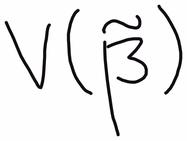

In [5]:
print(ds)
sample = ds["train"][0]
print(sample.keys())
print(sample["latex"])
sample["image"]

In [6]:
import re
from collections import Counter

Latex_token_pattern= re.compile(r"\\[a-zA-Z]+|[^\s]")

def tokenize_latex(latex_str):

  return Latex_token_pattern.findall(latex_str)

In [7]:
sample_latex= ds["train"][0]["latex"]
print(tokenize_latex(sample_latex))

['V', '(', '\\tilde', '{', '\\beta', '}', ')']


In [8]:

DATA_DIR = r'E:\handwritten-equation-solver\data'
os.makedirs(DATA_DIR, exist_ok=True)

In [9]:
counter= Counter()
for examples in ds["train"]:

  tokens= tokenize_latex(examples["latex"])
  counter.update(tokens)

print(f"Total number of unique tokens found:{len(counter)}")
print("Most common tokens:", counter.most_common(20))

Total number of unique tokens found:222
Most common tokens: [('}', 706089), ('{', 706071), ('^', 156749), ('_', 146800), ('\\frac', 131497), ('1', 122275), ('2', 114053), ('x', 107757), ('=', 102519), (')', 102415), ('(', 102331), ('i', 83552), ('t', 76014), ('a', 70742), ('r', 63997), ('-', 63629), ('m', 63331), ('0', 61669), ('\\', 55272), ('d', 50639)]


In [10]:
MIN_FREQ = 5
kept_tokens = [tok for tok, freq in counter.items() if freq >= MIN_FREQ]

In [11]:
SPECIAL_TOKENS = ["<pad>", "<sos>", "<eos>", "<unk>"]
vocab = SPECIAL_TOKENS + sorted(kept_tokens)

token2id = {tok: idx for idx, tok in enumerate(vocab)}
id2token = {idx: tok for tok, idx in token2id.items()}

PAD_ID = token2id["<pad>"]
SOS_ID = token2id["<sos>"]
EOS_ID = token2id["<eos>"]
UNK_ID = token2id["<unk>"]

print(f"Final vocab size: {len(vocab)}")

Final vocab size: 224


In [12]:
def encode_latex(latex_str, max_len=None):

  tokens = tokenize_latex(latex_str)
  ids = [SOS_ID] + [token2id.get(t, UNK_ID) for t in tokens] + [EOS_ID]

  if max_len:
    ids= ids[:max_len]

  return ids

In [13]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms

In [14]:
transform= transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128,512)),
    transforms.ToTensor(),
    transforms.Normalize((0.5),(0.5))
])

In [15]:
from datasets.config import HF_DATASETS_CACHE
class CustomDataset(Dataset):

  def __init__(self,hf_dataset, transform, max_len=150):

    self.ds= hf_dataset
    self.transform= transform
    self.max_len= max_len

  def __len__(self):

    return len(self.ds)

  def __getitem__(self,idx):

    example = self.ds[idx]
    image = example["image"].convert("RGB")
    image = self.transform(image)
    latex= example["latex"]
    token_ids= encode_latex(latex, max_len=self.max_len)

    return image, torch.tensor(token_ids, dtype= torch.long)

train_dataset= CustomDataset(ds["train"], transform)

In [16]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch,pad_id):

  images,sequence= zip(*batch)
  images = torch.stack(images, dim=0)  #(B, 1, H, W)
  sequences = pad_sequence(sequence, batch_first=True, padding_value=pad_id) #(B, T)
  return images,sequences

In [17]:
from torch.utils.data import DataLoader
from functools import partial

batch_size= 32
train_loader= DataLoader(train_dataset, batch_size= batch_size, shuffle= True,
                         collate_fn= partial(collate_fn,pad_id= PAD_ID), num_workers= 0)


In [18]:
from PIL import Image
import torchvision.transforms.functional as TF

class ResizeWithPad:
    def __init__(self, target_h=128, target_w=512, fill=255):
        self.target_h = target_h
        self.target_w = target_w
        self.fill = fill

    def __call__(self, img):
        w, h = img.size
        scale = min(self.target_w / w, self.target_h / h)
        new_w, new_h = int(w * scale), int(h * scale)
        img = img.resize((new_w, new_h), Image.BILINEAR)

        pad_w = self.target_w - new_w
        pad_h = self.target_h - new_h
        padding = (pad_w // 2, pad_h // 2, pad_w - pad_w // 2, pad_h - pad_h // 2)
        img = TF.pad(img, padding, fill=self.fill)
        return img

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    ResizeWithPad(target_h=128, target_w=512, fill=255),
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5))
])

train_dataset = CustomDataset(ds["train"], transform)
val_dataset = CustomDataset(ds["val"], transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                           collate_fn=partial(collate_fn, pad_id=PAD_ID), num_workers=0)

In [19]:
imgs, seqs = next(iter(train_loader))
print(imgs.shape, seqs.shape)

torch.Size([32, 1, 128, 512]) torch.Size([32, 55])


**CNN Encoder**

In [1]:
import math
import torch, torch.nn as nn
import torchvision as tv

def sinusoid_1d(n, d, device=None):
    pos = torch.arange(n, device=device).float().unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2, device=device).float() * (-math.log(10000.0) / d))
    pe = torch.zeros(n, d, device=device)
    pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
    return pe

class PositionalEncoding2D(nn.Module):
    # half the channels encode the row, half the column -> (H, W, d_model)
    def __init__(self, d_model):
        super().__init__(); assert d_model % 4 == 0; self.d = d_model
    def forward(self, H, W, device):
        d = self.d // 2
        pe_h = sinusoid_1d(H, d, device)[:, None, :].expand(H, W, d)
        pe_w = sinusoid_1d(W, d, device)[None, :, :].expand(H, W, d)
        return torch.cat([pe_h, pe_w], dim=-1)

class ImageEncoder(nn.Module):
    # ResNet-34 up to layer3 -> for a 128x512 input: 8x64 = 512 tokens
    def __init__(self, d_model=384, nhead=8, n_layers=3, dim_ff=1536, dropout=0.1, pretrained=True):
        super().__init__()
        r = tv.models.resnet34(weights=tv.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)

        # 1-channel input: sum the pretrained RGB filters so they stay useful
        conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
        conv1.weight.data.copy_(r.conv1.weight.data.sum(1, keepdim=True))

        # layer3 stride (2,1): halve height only, keep horizontal resolution
        r.layer3[0].conv1.stride = (2, 1)
        r.layer3[0].downsample[0].stride = (2, 1)

        self.stem = nn.Sequential(conv1, r.bn1, r.relu, r.maxpool)
        self.body = nn.Sequential(r.layer1, r.layer2, r.layer3)   # output: 256 channels
        self.proj = nn.Conv2d(256, d_model, 1)
        self.norm = nn.LayerNorm(d_model)
        self.pe2d = PositionalEncoding2D(d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_ff, dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d_model),
                                                 enable_nested_tensor=False)

    def forward(self, x):                                   # x: (B, 1, 128, 512), values in [-1, 1]
        f = self.proj(self.body(self.stem(x)))              # (B, D, 8, 64)
        B, D, Hh, Ww = f.shape
        f = self.norm(f.permute(0, 2, 3, 1))                # (B, 8, 64, D)
        f = f + self.pe2d(Hh, Ww, f.device).to(f.dtype)     # position added AFTER the norm
        return self.transformer(f.reshape(B, Hh * Ww, D))   # (B, 512, D)

In [20]:
import torch.nn as nn
import math

class PositionalEncoding2D(nn.Module):

  def __init__(self, d_model):

    super().__init__()
    assert d_model % 4 == 0, "d_model must be divisible by 4 for 2D sin-cos encoding"
    self.d_model = d_model

  def forward(self, H, W, device):

    d = self.d_model // 2
    pe = torch.zeros(H, W, self.d_model, device=device)

    div_term = torch.exp(torch.arange(0, d, 2, device=device).float() * (-math.log(10000.0) / d))

    pos_h = torch.arange(H, device=device).unsqueeze(1).float()
    pos_w = torch.arange(W, device=device).unsqueeze(1).float()

    pe_h = torch.zeros(H, d, device=device)
    pe_h[:, 0::2] = torch.sin(pos_h * div_term)
    pe_h[:, 1::2] = torch.cos(pos_h * div_term)

    pe_w = torch.zeros(W, d, device=device)
    pe_w[:, 0::2] = torch.sin(pos_w * div_term)
    pe_w[:, 1::2] = torch.cos(pos_w * div_term)

    pe[:, :, :d] = pe_h.unsqueeze(1).expand(H, W, d)
    pe[:, :, d:] = pe_w.unsqueeze(0).expand(H, W, d)

    return pe  # (H, W, d_model)

In [21]:
import torch.nn as nn

class CNNEncoder(nn.Module):

  def __init__(self, out_dim=256):

    super().__init__()

    self.cnn= nn.Sequential(
        nn.Conv2d(1, 32, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(32, 64, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(64, 128, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(128, out_dim, 3, padding=1),
        nn.ReLU(),
    )

    self.pos_encoding_2d = PositionalEncoding2D(out_dim)

  def forward(self, x):

    features = self.cnn(x)                # (B, C, H', W')
    B, C, H, W = features.shape

    pos_enc = self.pos_encoding_2d(H, W, x.device)     # (H, W, C)
    pos_enc = pos_enc.permute(2, 0, 1).unsqueeze(0)     # (1, C, H, W)
    features = features + pos_enc

    features = features.flatten(2)        # (B, C, H'*W')
    features = features.permute(0, 2, 1)  # (B, H'*W', C)
    return features

**Transformer Decoder**

In [22]:
import math

class PositionalEncoding(nn.Module):

  def __init__(self, d_model, max_len=200):

    super().__init__()

    pe= torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len).unsqueeze(1).float()
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model)

  def forward(self,x):

    return x+ self.pe[:, :x.size(1)]

class EquationTransformer(nn.Module):

  def __init__(self, vocab_size, d_model=384, nhead=8, num_decoder_layers=6, dim_ff=1024, dropout=0.1):

    super().__init__()

    self.encoder= CNNEncoder(out_dim=d_model)
    self.token_embed= nn.Embedding(vocab_size, d_model, padding_idx= PAD_ID)
    self.pos_encoding= PositionalEncoding(d_model)

    decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True
            )

    self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_decoder_layers)
    self.fc_out = nn.Linear(d_model, vocab_size)

  def generate_causal_mask(self, size, device):

    mask = torch.triu(torch.ones(size, size, device=device), diagonal=1).bool()
    return mask

  def forward(self, images, tgt_tokens):

    memory = self.encoder(images)  #(B, S, d_model)

    tgt_emb = self.token_embed(tgt_tokens)  #(B, T, d_model)
    tgt_emb = self.pos_encoding(tgt_emb)

    tgt_mask = self.generate_causal_mask(tgt_tokens.size(1), tgt_tokens.device)
    tgt_key_padding_mask = (tgt_tokens == PAD_ID)   # (B, T)

    out = self.transformer_decoder(
            tgt=tgt_emb, memory=memory,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
         )
    logits = self.fc_out(out)  #(B, T, vocab_size)
    return logits



**Training Loop**

In [29]:
import os
import time
import shutil

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EquationTransformer(vocab_size=len(vocab), d_model=384, nhead=8, num_decoder_layers=6, dim_ff=1024, dropout=0.1).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

BACKUP_DIR = r'E:\model_checkpoints'
os.makedirs(BACKUP_DIR, exist_ok=True)

def train_one_epoch(model, loader, sampling_prob=0.0):
    model.train()
    total_loss = 0
    for images, seqs in loader:
        images, seqs = images.to(device), seqs.to(device)

        decoder_input = seqs[:, :-1].clone()  # everything except the last token
        target = seqs[:, 1:]                  # everything except <sos>

        if sampling_prob > 0:
            # First pass (no grad):get the model's own predictions to sample from
            with torch.no_grad():
                first_logits = model(images, decoder_input)   # (B, T-1, V)
                first_preds = first_logits.argmax(-1)          # (B, T-1)

            # first_preds[:, i] predicts decoder_input[:, i+1] (shifted by one)
            # Randomly replace some ground-truth input tokens with the model's own predictions,
            # skipping the first position (which is always <sos>) and any PAD positions.
            mask = (torch.rand(decoder_input[:, 1:].shape, device=device) < sampling_prob)
            mask &= (decoder_input[:, 1:] != PAD_ID)
            decoder_input[:, 1:][mask] = first_preds[:, :-1][mask]

        optimizer.zero_grad()
        logits = model(images, decoder_input)   # (B, T-1, V) — real forward pass, gradients flow
        loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)

NUM_EPOCHS = 25         # bump this up from your current value to fine-tune with scheduled sampling
MAX_SAMPLING_PROB = 0.25  # cap at 25% — never fully remove teacher forcing, keeps training stable
start_epoch = 0

# Find the latest checkpoint, if any, and resume from it
existing = [f for f in os.listdir(DATA_DIR) if f.startswith("checkpoint_v2_epoch")]
if existing:
    latest = max(existing, key=lambda f: int(f.split("epoch")[1].split(".")[0]))
    checkpoint = torch.load(f"{DATA_DIR}/{latest}")
    model.load_state_dict(checkpoint['model'])
    optimizer.load_state_dict(checkpoint['optimizer'])
    start_epoch = checkpoint['epoch']
    print(f"Resuming from epoch {start_epoch}")

for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_start = time.time()

    # Ramp sampling_prob linearly from 0 -> MAX_SAMPLING_PROB across training
    sampling_prob = MAX_SAMPLING_PROB * (epoch / max(1, NUM_EPOCHS - 1))
    avg_loss = train_one_epoch(model, train_loader, sampling_prob=sampling_prob)

    epoch_time = time.time() - epoch_start
    epochs_left = NUM_EPOCHS - (epoch + 1)
    eta_min = epoch_time * epochs_left / 60

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - loss: {avg_loss:.4f} - sampling_prob: {sampling_prob:.2f} - "
          f"time: {epoch_time/60:.1f} min - ETA: {eta_min:.1f} min remaining")

    checkpoint_path = f"{DATA_DIR}/checkpoint_v2_epoch{epoch+1}.pt"
    torch.save({
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'epoch': epoch + 1,
    }, checkpoint_path)

    shutil.copy(checkpoint_path, f"{BACKUP_DIR}/checkpoint_v2_latest.pt")

Resuming from epoch 25


In [28]:
import os
import time
import shutil

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EquationTransformer(vocab_size=len(vocab), d_model=384, nhead=8, num_decoder_layers=6, dim_ff=1024, dropout=0.1).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

BACKUP_DIR = r'E:\model_checkpoints'
os.makedirs(BACKUP_DIR, exist_ok=True)

def train_one_epoch(model, loader, sampling_prob=0.0):
    model.train()
    total_loss = 0
    for images, seqs in loader:
        images, seqs = images.to(device), seqs.to(device)

        decoder_input = seqs[:, :-1].clone()
        target = seqs[:, 1:]

        if sampling_prob > 0:
            with torch.no_grad():
                first_logits = model(images, decoder_input)
                first_preds = first_logits.argmax(-1)

            mask = (torch.rand(decoder_input[:, 1:].shape, device=device) < sampling_prob)
            mask &= (decoder_input[:, 1:] != PAD_ID)
            decoder_input[:, 1:][mask] = first_preds[:, :-1][mask]

        optimizer.zero_grad()
        logits = model(images, decoder_input)
        loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)

# --- Warm start from pre-PE checkpoint, but reset epoch counter and optimizer ---
existing = [f for f in os.listdir(DATA_DIR) if f.startswith("checkpoint_v2_epoch")]
if existing:
    latest = max(existing, key=lambda f: int(f.split("epoch")[1].split(".")[0]))
    checkpoint = torch.load(f"{DATA_DIR}/{latest}")
    model.load_state_dict(checkpoint['model'])
    print(f"Loaded weights from {latest} as warm start for PE fine-tuning")

optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)  # fresh optimizer, not resumed

NUM_EPOCHS = 10
MAX_SAMPLING_PROB = 0.25
start_epoch = 0

EVAL_EVERY = 2          # run beam-search eval every N epochs
EVAL_N = 100             # val samples per eval, matches your earlier eval calls
PATIENCE = 3             # stop if exact match doesn't improve for this many evals
best_exact_match = -1
epochs_since_improvement = 0

for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_start = time.time()

    sampling_prob = MAX_SAMPLING_PROB * (epoch / max(1, NUM_EPOCHS - 1))
    avg_loss = train_one_epoch(model, train_loader, sampling_prob=sampling_prob)

    epoch_time = time.time() - epoch_start
    epochs_left = NUM_EPOCHS - (epoch + 1)
    eta_min = epoch_time * epochs_left / 60

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - loss: {avg_loss:.4f} - sampling_prob: {sampling_prob:.2f} - "
          f"time: {epoch_time/60:.1f} min - ETA: {eta_min:.1f} min remaining")

    checkpoint_path = f"{DATA_DIR}/checkpoint_pe_epoch{epoch+1}.pt"
    torch.save({
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'epoch': epoch + 1,
    }, checkpoint_path)
    shutil.copy(checkpoint_path, f"{BACKUP_DIR}/checkpoint_pe_latest.pt")

    # --- periodic eval + early stopping ---
    if (epoch + 1) % EVAL_EVERY == 0:
        exact_match, avg_cer = evaluate_beam(model, val_dataset, n=EVAL_N, beam_width=5)
        print(f"  [eval] exact_match={exact_match:.2f}%  avg_cer={avg_cer:.2f}%")

        if exact_match > best_exact_match:
            best_exact_match = exact_match
            epochs_since_improvement = 0
            best_path = f"{DATA_DIR}/checkpoint_pe_best.pt"
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1}, best_path)
            shutil.copy(best_path, f"{BACKUP_DIR}/checkpoint_pe_best.pt")
            print(f"  [eval] new best exact_match={best_exact_match:.2f}% — saved checkpoint_pe_best.pt")
        else:
            epochs_since_improvement += 1
            print(f"  [eval] no improvement for {epochs_since_improvement}/{PATIENCE} eval(s)")

        if epochs_since_improvement >= PATIENCE:
            print(f"Early stopping: no improvement in exact_match for {PATIENCE} consecutive evals.")
            break

Loaded weights from checkpoint_v2_epoch25.pt as warm start for PE fine-tuning
Epoch 1/10 - loss: 2.7383 - sampling_prob: 0.00 - time: 41.9 min - ETA: 376.8 min remaining


KeyboardInterrupt: 

**Inference**

In [23]:
@torch.no_grad()
def predict(model, image_tensor, max_len=150):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  #(1, 1, H, W)
    memory = model.encoder(image_tensor)

    generated = [SOS_ID]
    for _ in range(max_len):
        tgt = torch.tensor([generated], device=device)
        tgt_emb = model.pos_encoding(model.token_embed(tgt))
        tgt_mask = model.generate_causal_mask(tgt_emb.size(1), device)

        out = model.transformer_decoder(tgt_emb, memory, tgt_mask=tgt_mask)
        logits = model.fc_out(out[:, -1, :])   #only need last position
        next_token = logits.argmax(-1).item()

        if next_token == EOS_ID:
            break
        generated.append(next_token)

    tokens = [id2token[i] for i in generated[1:]]  #drop <sos>
    return "".join(tokens)

**Evaluation**

In [24]:
@torch.no_grad()
def predict_beam(model, image_tensor, beam_width=10, max_len=150, length_penalty=0.7):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  # (1, 1, H, W)
    memory = model.encoder(image_tensor)

    # Each beam: (token_id_list, cumulative_log_prob, finished)
    beams = [([SOS_ID], 0.0, False)]

    def norm_score(item):
        seq, score, _ = item
        return score / (len(seq) ** length_penalty)

    for _ in range(max_len):
        all_candidates = []

        for seq, score, finished in beams:
            if finished:
                # Keep finished beams as-is so they can still win
                all_candidates.append((seq, score, finished))
                continue

            tgt = torch.tensor([seq], device=device)
            tgt_emb = model.pos_encoding(model.token_embed(tgt))
            tgt_mask = model.generate_causal_mask(tgt_emb.size(1), device)

            out = model.transformer_decoder(tgt_emb, memory, tgt_mask=tgt_mask)
            logits = model.fc_out(out[:, -1, :])          # (1, V)
            log_probs = torch.log_softmax(logits, dim=-1)  # (1, V)

            topk_log_probs, topk_ids = log_probs.topk(beam_width, dim=-1)

            for k in range(beam_width):
                token_id = topk_ids[0, k].item()
                token_log_prob = topk_log_probs[0, k].item()
                new_seq = seq + [token_id]
                new_score = score + token_log_prob
                new_finished = (token_id == EOS_ID)
                all_candidates.append((new_seq, new_score, new_finished))

        # Length-normalized score so beams aren't biased toward short sequences
        all_candidates.sort(key=norm_score, reverse=True)
        beams = all_candidates[:beam_width]

        if all(finished for _, _, finished in beams):
            break

    best_seq, _, _ = max(beams, key=norm_score)
    tokens = [id2token[i] for i in best_seq[1:] if i != EOS_ID]  # drop <sos>, drop trailing <eos>
    return "".join(tokens)

In [25]:
def predict_one(model, image, beam_width=5):
    return predict_beam(model, image, beam_width=beam_width)

In [26]:
!pip install editdistance
import editdistance

def evaluate_beam(model, val_dataset, n=100, beam_width=10):
    exact_matches = 0
    total_cer = 0
    for i in range(n):
        image, target_ids = val_dataset[i]
        pred_latex = predict_beam(model, image, beam_width=10)
        target_latex = "".join([id2token[t.item()] for t in target_ids if t.item() not in (PAD_ID, SOS_ID, EOS_ID)])

        if pred_latex == target_latex:
            exact_matches += 1
        total_cer += editdistance.eval(pred_latex, target_latex) / max(len(target_latex), 1)

    print(f"Exact match: {exact_matches/n:.2%}, Avg char error rate: {total_cer/n:.2%}")
    return exact_matches/n,total_cer/n


In [30]:
val_dataset = CustomDataset(ds["val"], transform)

image, target_ids = val_dataset[0]
pred = predict(model, image)
target = "".join([id2token[t.item()] for t in target_ids if t.item() not in (PAD_ID, SOS_ID, EOS_ID)])
print("Predicted:", pred)
print("Target:   ", target)

# Full evaluation
evaluate_beam(model , val_dataset, n=100, beam_width=10)

Predicted: }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
Target:    \frac{\partial\psi}{\partialt}=P\psi
Exact match: 0.00%, Avg char error rate: 949.98%


(0.0, 9.499773010631085)

In [31]:
import re
from collections import Counter, defaultdict
 
try:
    import Levenshtein
    def char_edit_distance(a, b):
        return Levenshtein.distance(a, b)
except ImportError:
    def char_edit_distance(a, b):
        # fallback pure-python edit distance
        m, n = len(a), len(b)
        dp = list(range(n + 1))
        for i in range(1, m + 1):
            prev, dp[0] = dp[0], i
            for j in range(1, n + 1):
                cur = dp[j]
                dp[j] = prev if a[i-1] == b[j-1] else 1 + min(prev, dp[j], dp[j-1])
                prev = cur
        return dp[n]
 
 
def ids_to_str(ids, id2token, skip_ids):
    return "".join(id2token[t.item() if hasattr(t, "item") else t]
                   for t in ids if (t.item() if hasattr(t, "item") else t) not in skip_ids)
 
 
def tokenize_latex_display(s):
    """Split into LaTeX-ish tokens: commands like \\frac, braces, single chars."""
    return re.findall(r"\\[a-zA-Z]+|.", s)
 
 
def run_error_analysis(model, val_dataset, id2token, PAD_ID, SOS_ID, EOS_ID,
                        n=100, beam_width=5, length_bucket_size=10):
    skip_ids = (PAD_ID, SOS_ID, EOS_ID)
    results = []
 
    for i in range(min(n, len(val_dataset))):
        image, target_ids = val_dataset[i]
        target = ids_to_str(target_ids, id2token, skip_ids)
        pred = predict_one(model, image, beam_width=beam_width)
 
        exact = (pred.strip() == target.strip())
        cer = char_edit_distance(pred, target) / max(1, len(target))
 
        pred_tokens = tokenize_latex_display(pred)
        target_tokens = tokenize_latex_display(target)
        tok_err = char_edit_distance("".join(pred_tokens), "".join(target_tokens)) / max(1, len(target_tokens))
 
        results.append({
            "idx": i,
            "pred": pred,
            "target": target,
            "exact": exact,
            "cer": cer,
            "target_len": len(target),
            "pred_tokens": pred_tokens,
            "target_tokens": target_tokens,
        })
 
    # --- Summary stats ---
    n_total = len(results)
    n_exact = sum(r["exact"] for r in results)
    avg_cer = sum(r["cer"] for r in results) / n_total
    print(f"Exact match: {n_exact/n_total*100:.2f}%  |  Avg CER: {avg_cer*100:.2f}%\n")
 
    # --- Length bucket breakdown ---
    print("=== Accuracy by target length bucket ===")
    buckets = defaultdict(list)
    for r in results:
        b = r["target_len"] // length_bucket_size * length_bucket_size
        buckets[b].append(r)
    for b in sorted(buckets):
        bucket_results = buckets[b]
        acc = sum(r["exact"] for r in bucket_results) / len(bucket_results)
        cer = sum(r["cer"] for r in bucket_results) / len(bucket_results)
        print(f"  len {b:3d}-{b+length_bucket_size-1:<3d}: n={len(bucket_results):3d}  "
              f"exact={acc*100:5.1f}%  cer={cer*100:5.1f}%")
 
    # --- Most common wrong tokens (substitution/missing) ---
    print("\n=== Most frequently mismatched tokens (failed cases only) ===")
    token_error_counter = Counter()
    for r in results:
        if r["exact"]:
            continue
        pred_set = Counter(r["pred_tokens"])
        target_set = Counter(r["target_tokens"])
        # tokens present in target but missing/short in pred -> likely "model failed to produce"
        for tok, cnt in target_set.items():
            missing = max(0, cnt - pred_set.get(tok, 0))
            if missing:
                token_error_counter[tok] += missing
    for tok, cnt in token_error_counter.most_common(20):
        print(f"  {tok!r:15s}  missed {cnt} times")
 
    # --- Structural token check (braces, \frac, ^, _) ---
    print("\n=== Structural token accuracy (failed cases only) ===")
    structural = ["{", "}", "\\frac", "^", "_", "\\left", "\\right"]
    for s in structural:
        target_count = sum(r["target_tokens"].count(s) for r in results if not r["exact"])
        pred_count = sum(r["pred_tokens"].count(s) for r in results if not r["exact"])
        if target_count:
            print(f"  {s!r:10s} target={target_count:4d}  pred={pred_count:4d}  "
                  f"diff={pred_count - target_count:+d}")
 
    # --- Worst 10 examples by CER, for manual inspection ---
    print("\n=== Worst 10 examples (by CER) ===")
    worst = sorted([r for r in results if not r["exact"]], key=lambda r: -r["cer"])[:10]
    for r in worst:
        print(f"  [{r['idx']}] CER={r['cer']*100:.1f}%")
        print(f"      pred:   {r['pred']}")
        print(f"      target: {r['target']}")
 
    return results
 

In [32]:
results = run_error_analysis(model, val_dataset, id2token, PAD_ID, SOS_ID, EOS_ID,
                               n=100, beam_width=5)

Exact match: 0.00%  |  Avg CER: 949.98%

=== Accuracy by target length bucket ===
  len   0-9  : n=  8  exact=  0.0%  cer=4107.3%
  len  10-19 : n= 28  exact=  0.0%  cer=1023.8%
  len  20-29 : n= 35  exact=  0.0%  cer=633.7%
  len  30-39 : n= 20  exact=  0.0%  cer=429.1%
  len  40-49 : n=  6  exact=  0.0%  cer=331.5%
  len  50-59 : n=  1  exact=  0.0%  cer=278.4%
  len  60-69 : n=  2  exact=  0.0%  cer=223.0%

=== Most frequently mismatched tokens (failed cases only) ===
  '{'              missed 250 times
  '_'              missed 87 times
  '^'              missed 56 times
  '='              missed 55 times
  '('              missed 51 times
  ')'              missed 51 times
  'x'              missed 37 times
  'i'              missed 37 times
  '2'              missed 36 times
  '1'              missed 36 times
  'r'              missed 34 times
  't'              missed 30 times
  '-'              missed 30 times
  'a'              missed 29 times
  '0'              missed 27 time

In [33]:
for r in results:
    if r["target_len"] <= 9 and not r["exact"]:
        print(f"[{r['idx']}] CER={r['cer']*100:.1f}%")
        print(f"    pred:   {r['pred']}")
        print(f"    target: {r['target']}")

[44] CER=1655.6%
    pred:   }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
    target: \tilde{Q}
[46] CER=7500.0%
    pred:   }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
    target: -s
[47] CER=1655.6%
    pred:   }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
    target: \sqrt{-7}
[53] CER=1655.6%
    pred:   }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
    target: \sqrt{-1}
[56] CER=1862.5%
    pred:   }}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}}
    target: \sqrt{i

In [34]:
# Try these variants on the same 100 val samples, no retraining needed:
evaluate_beam(model, val_dataset, n=100, beam_width=5)  # current: length_penalty hardcoded at 0.7 inside predict_beam

# Temporarily test alternatives by calling predict_beam directly with different length_penalty:
for lp in [0.0, 0.3, 0.5, 0.7, 1.0]:
    exact = 0
    for i in range(100):
        image, target_ids = val_dataset[i]
        target = "".join([id2token[t.item()] for t in target_ids if t.item() not in (PAD_ID, SOS_ID, EOS_ID)])
        pred = predict_beam(model, image, beam_width=5, length_penalty=lp)
        if pred == target:
            exact += 1
    print(f"length_penalty={lp}: exact match = {exact}%")

KeyboardInterrupt: 